<a href="https://colab.research.google.com/github/shingihorton/IS4487_Portfolio/blob/main/IS4487_Shingi_assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [ ]:
#Loading necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
import seaborn as sns

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [ ]:
#Importing Historical dataset
df = pd.read_csv("https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_historical_data.csv")
df.describe()

,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The negative income stands out.
The age column has a maximum age of 132 which seems like an outlier that doesn't exist.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [ ]:
# 2.1 Checking for outliers
# Check potential outliers using the IQR method

for col in ["income", "age", "num_dependents", "num_accts"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    print(f"{col}: {outlier_count} potential outliers")

  # Remove clearly invalid outlier values

df = df[
    (df["income"] > 0) &
    (df["age"] <= 100) &
    (df["num_accts"] < 5)]
df.shape

income: 2241 potential outliers
age: 1025 potential outliers
num_dependents: 4160 potential outliers
num_accts: 1922 potential outliers


(29499, 15)

In [ ]:
#2.2 Handling missing data
#Checking for missing values
df.isnull().sum()
#Dropping missing values
df = df.dropna(subset = ["new_car"])
#Checking for duplicates
df.duplicated().sum()
#Removing duplicates
df = df.drop_duplicates()
#Double checking
df.shape

(29494, 15)

In [ ]:
#2.3 Removing variables that are not helpful
df = df.drop(columns = ["customer_id", "product"])
df.columns

Index(['answered', 'income', 'female', 'age', 'job', 'num_dependents', 'rent',
       'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile'],
      dtype='object')

In [ ]:
df.shape

(29494, 13)

In [ ]:
df_clean = df.copy()
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29494 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29494 non-null  int64  
 1   income          29494 non-null  int64  
 2   female          29494 non-null  object 
 3   age             29494 non-null  int64  
 4   job             29494 non-null  int64  
 5   num_dependents  29494 non-null  int64  
 6   rent            29494 non-null  int64  
 7   own_res         29494 non-null  int64  
 8   new_car         29494 non-null  float64
 9   chk_acct        29494 non-null  int64  
 10  sav_acct        29494 non-null  int64  
 11  num_accts       29494 non-null  int64  
 12  mobile          29494 non-null  int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 3.2+ MB


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I cleaned the outliers by using the reasonable max values and minimum value. I removed negative income and removed ages over 100 and rows with more that 5 accounts. I chose these because they are pragmatic.

2.6 I removed the customer_id because it's an identifier. I also removed the product column because that comes after they have already called and that will influence the model.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [ ]:
# Creating boolean datatype for "answered"
df_clean["answered"] = df_clean["answered"].astype(bool)

# Converting female column from 'F'/'M' strings to 1/0 integers
df_clean["female"] = df_clean["female"].map({"F": 1, "M": 0}).fillna(0).astype(int)

# Converting new_car to integer
df_clean["new_car"] = df_clean["new_car"].astype(int)

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29494 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   answered        29494 non-null  bool 
 1   income          29494 non-null  int64
 2   female          29494 non-null  int64
 3   age             29494 non-null  int64
 4   job             29494 non-null  int64
 5   num_dependents  29494 non-null  int64
 6   rent            29494 non-null  int64
 7   own_res         29494 non-null  int64
 8   new_car         29494 non-null  int64
 9   chk_acct        29494 non-null  int64
 10  sav_acct        29494 non-null  int64
 11  num_accts       29494 non-null  int64
 12  mobile          29494 non-null  int64
dtypes: bool(1), int64(12)
memory usage: 3.0 MB


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [ ]:
# Convert categorical-coded variables to category type

categorical_cols = ["job", "chk_acct", "sav_acct"]

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype("category")

df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,category
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,category


In [ ]:
# Replace coded categories with readable labels

df_clean["job"] = df_clean["job"].cat.rename_categories({
    0: "Unemployed",
    1: "Entry Level",
    2: "Midlevel",
    3: "Management / Professional"
})

df_clean["chk_acct"] = df_clean["chk_acct"].cat.rename_categories({
    0: "No Checking Account",
    1: "Less Than $200",
    2: "$200 to $2,000",
    3: "$2,000 to $35,000",
    4: "$35,000 or More"
})

df_clean["sav_acct"] = df_clean["sav_acct"].cat.rename_categories({
    0: "No Savings Account",
    1: "$100 to $500",
    2: "$500 to $2,000",
    3: "$2,000 to $35,000",
    4: "$35,000 or More"
})

# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



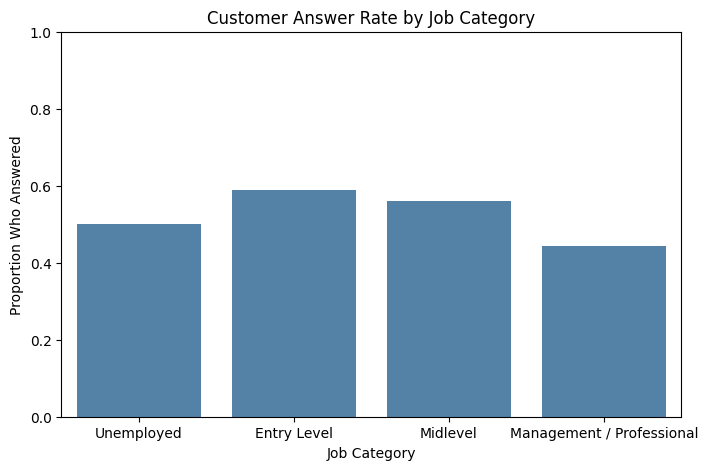

In [ ]:
# Chart 3.1 🔧
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="job",
    y="answered",
    errorbar=None,
    color="steelblue"
)

plt.title("Customer Answer Rate by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Proportion Who Answered")
plt.ylim(0, 1)

plt.show()

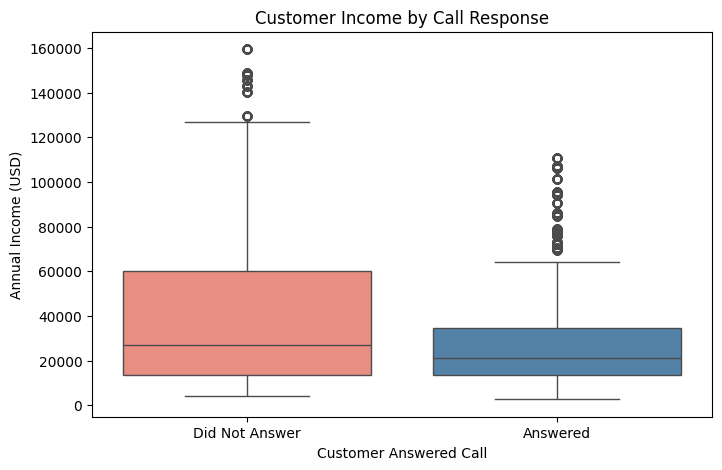

In [ ]:
# Chart 3.2 🔧
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="answered",
    y="income",
    hue="answered",
    legend=False,
    palette=["salmon", "steelblue"]
)

plt.title("Customer Income by Call Response")
plt.xlabel("Customer Answered Call")
plt.ylabel("Annual Income (USD)")
plt.xticks([0, 1], ["Did Not Answer", "Answered"])

plt.show()

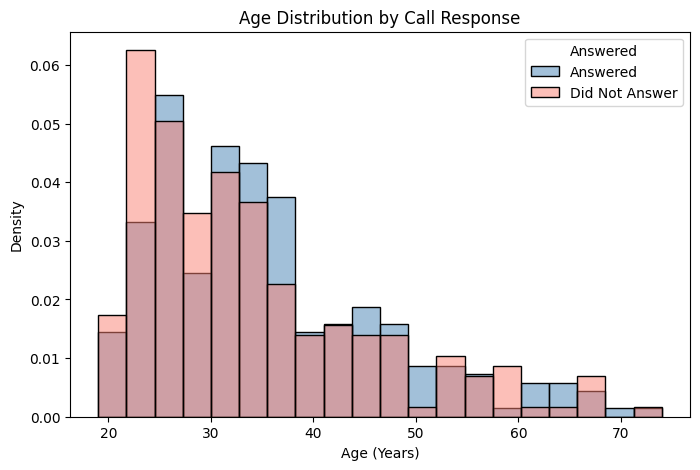

In [ ]:
# Chart 3.3 🔧
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="age",
    hue="answered",
    bins=20,
    multiple="layer",
    stat="density",
    common_norm=False,
    palette=["salmon", "steelblue"],
    alpha=0.5
)

plt.title("Age Distribution by Call Response")
plt.xlabel("Age (Years)")
plt.ylabel("Density")
plt.legend(title="Answered", labels=["Answered", "Did Not Answer"])

plt.show()

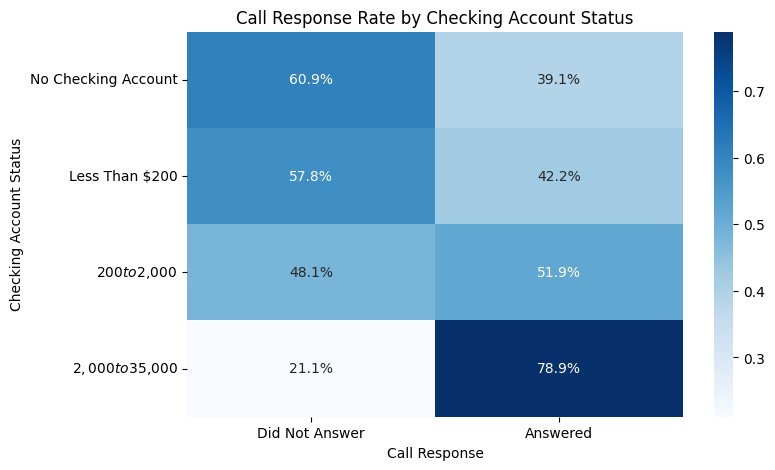

In [ ]:
# Chart 3.4 🔧
# Calculate response percentages within each checking-account category
chk_response = pd.crosstab(
    df_clean["chk_acct"],
    df_clean["answered"],
    normalize="index"
)

# Make the labels easier to read
chk_response.columns = ["Did Not Answer", "Answered"]

plt.figure(figsize=(8, 5))

sns.heatmap(
    chk_response,
    annot=True,
    fmt=".1%",
    cmap="Blues"
)

plt.title("Call Response Rate by Checking Account Status")
plt.xlabel("Call Response")
plt.ylabel("Checking Account Status")

plt.show()

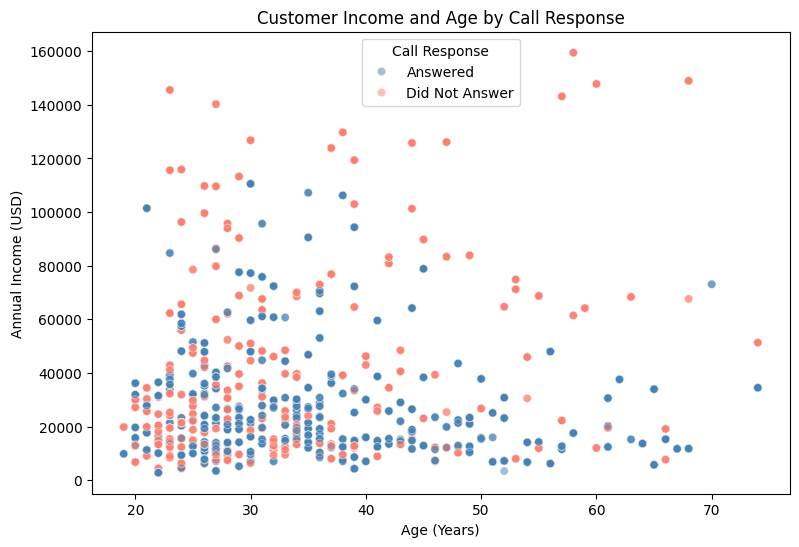

In [ ]:
# Chart 3.5 🔧
# Use a random sample so the chart remains readable
plot_data = df_clean.sample(n=3000, random_state=42).copy()

plot_data["response"] = plot_data["answered"].map({
    False: "Did Not Answer",
    True: "Answered"
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_data,
    x="age",
    y="income",
    hue="response",
    palette={
        "Did Not Answer": "salmon",
        "Answered": "steelblue"
    },
    alpha=0.5
)

plt.title("Customer Income and Age by Call Response")
plt.xlabel("Age (Years)")
plt.ylabel("Annual Income (USD)")
plt.legend(title="Call Response")

plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking account status, age and income seem to have the strongest relationship with the target variable.

3.7.  Job category seems to have a weak relationship with the target varible. It should not be removed as it connects to income which is an important predictor.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [ ]:
# Calculate the base probability of answering the scheduled call

base_probability = df_clean["answered"].mean()

print(f"Base probability of answering: {base_probability:.2%}")

Base probability of answering: 54.67%


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [ ]:
from sklearn.model_selection import train_test_split

# Independent variables and target variable
X = df_clean.drop(columns="answered")
y = df_clean["answered"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

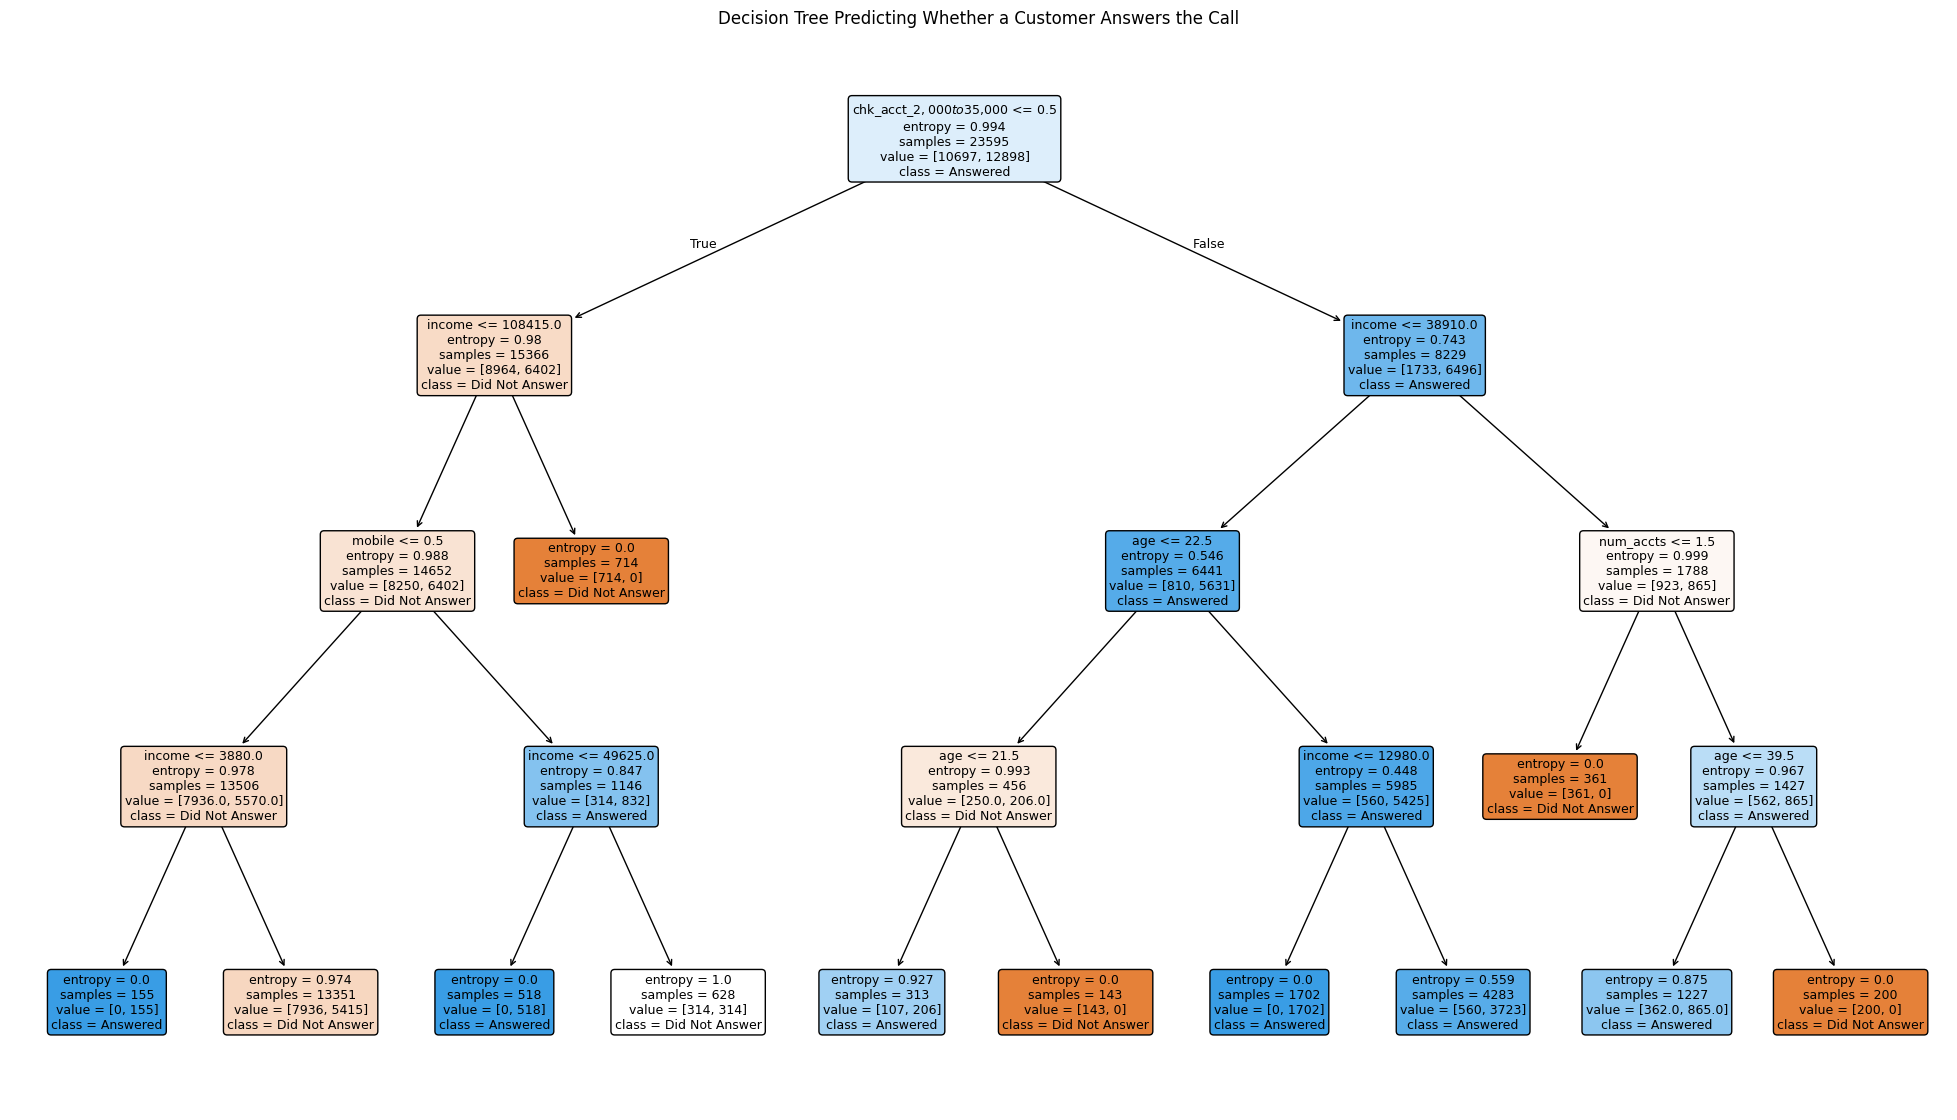

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Convert categorical variables into model-ready numeric columns
X_train_model = pd.get_dummies(X_train, drop_first=False, dtype=int)
X_test_model = pd.get_dummies(X_test, drop_first=False, dtype=int)

# Ensure the test set has the same columns as the training set
X_test_model = X_test_model.reindex(columns=X_train_model.columns, fill_value=0)

# Create and train the decision tree
tree_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)

tree_model.fit(X_train_model, y_train)

# Display the tree
plt.figure(figsize=(25, 14))

plot_tree(
    tree_model,
    feature_names=X_train_model.columns,
    class_names=["Did Not Answer", "Answered"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Predicting Whether a Customer Answers the Call")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [ ]:
from sklearn.metrics import accuracy_score

# Make predictions using the decision tree
y_pred_tree = tree_model.predict(X_test_model)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print(f"Decision tree accuracy: {tree_accuracy:.2%}")

Decision tree accuracy: 71.35%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The baseline was 54.67% and the decision tree has 71.35% accuracy. The difference is 16.68%

2. I think it's a significant amount for the business.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [ ]:
# Create and display the confusion matrix as a table

cm = confusion_matrix(y_test, y_pred_tree)

cm_table = pd.DataFrame(
    cm,
    index=["Actual: Did Not Answer", "Actual: Answered"],
    columns=["Predicted: Did Not Answer", "Predicted: Answered"]
)

cm_table


,Predicted: Did Not Answer,Predicted: Answered
Actual: Did Not Answer,2423,251
Actual: Answered,1439,1786


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

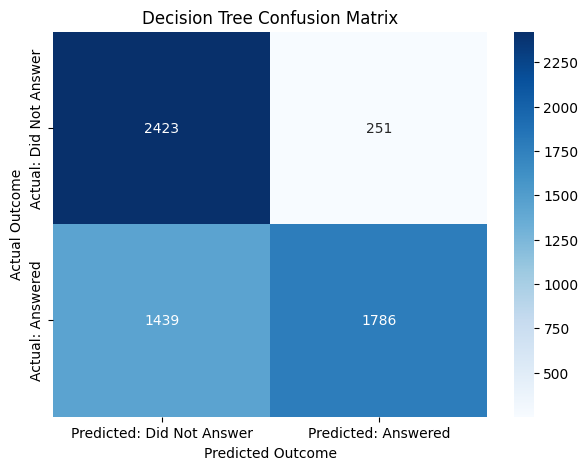

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [ ]:
# Extract confusion-matrix values
tn, fp, fn, tp = cm.ravel()

# Calculate profit from calls made based on the model
profit = (tp * 75) - (fp * 25)

print(f"True positives: {tp}")
print(f"False positives: {fp}")
print(f"Profit using the model: ${profit:,.2f}")

True positives: 1786
False positives: 251
Profit using the model: $127,675.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [ ]:
# Baseline: call every customer in the test set

true_answered = y_test.sum()
false_answered = len(y_test) - true_answered

default_profit = (true_answered * 75) - (false_answered * 25)

print(f"Customers who answered: {true_answered}")
print(f"Customers who did not answer: {false_answered}")
print(f"Default profit from calling everyone: ${default_profit:,.2f}")

Customers who answered: 3225
Customers who did not answer: 2674
Default profit from calling everyone: $175,025.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The difference in profit is $47350, with calling all customers resulting in more profits assuming all those that answer buy something.

2. Yes, it is a significant amount for the business.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

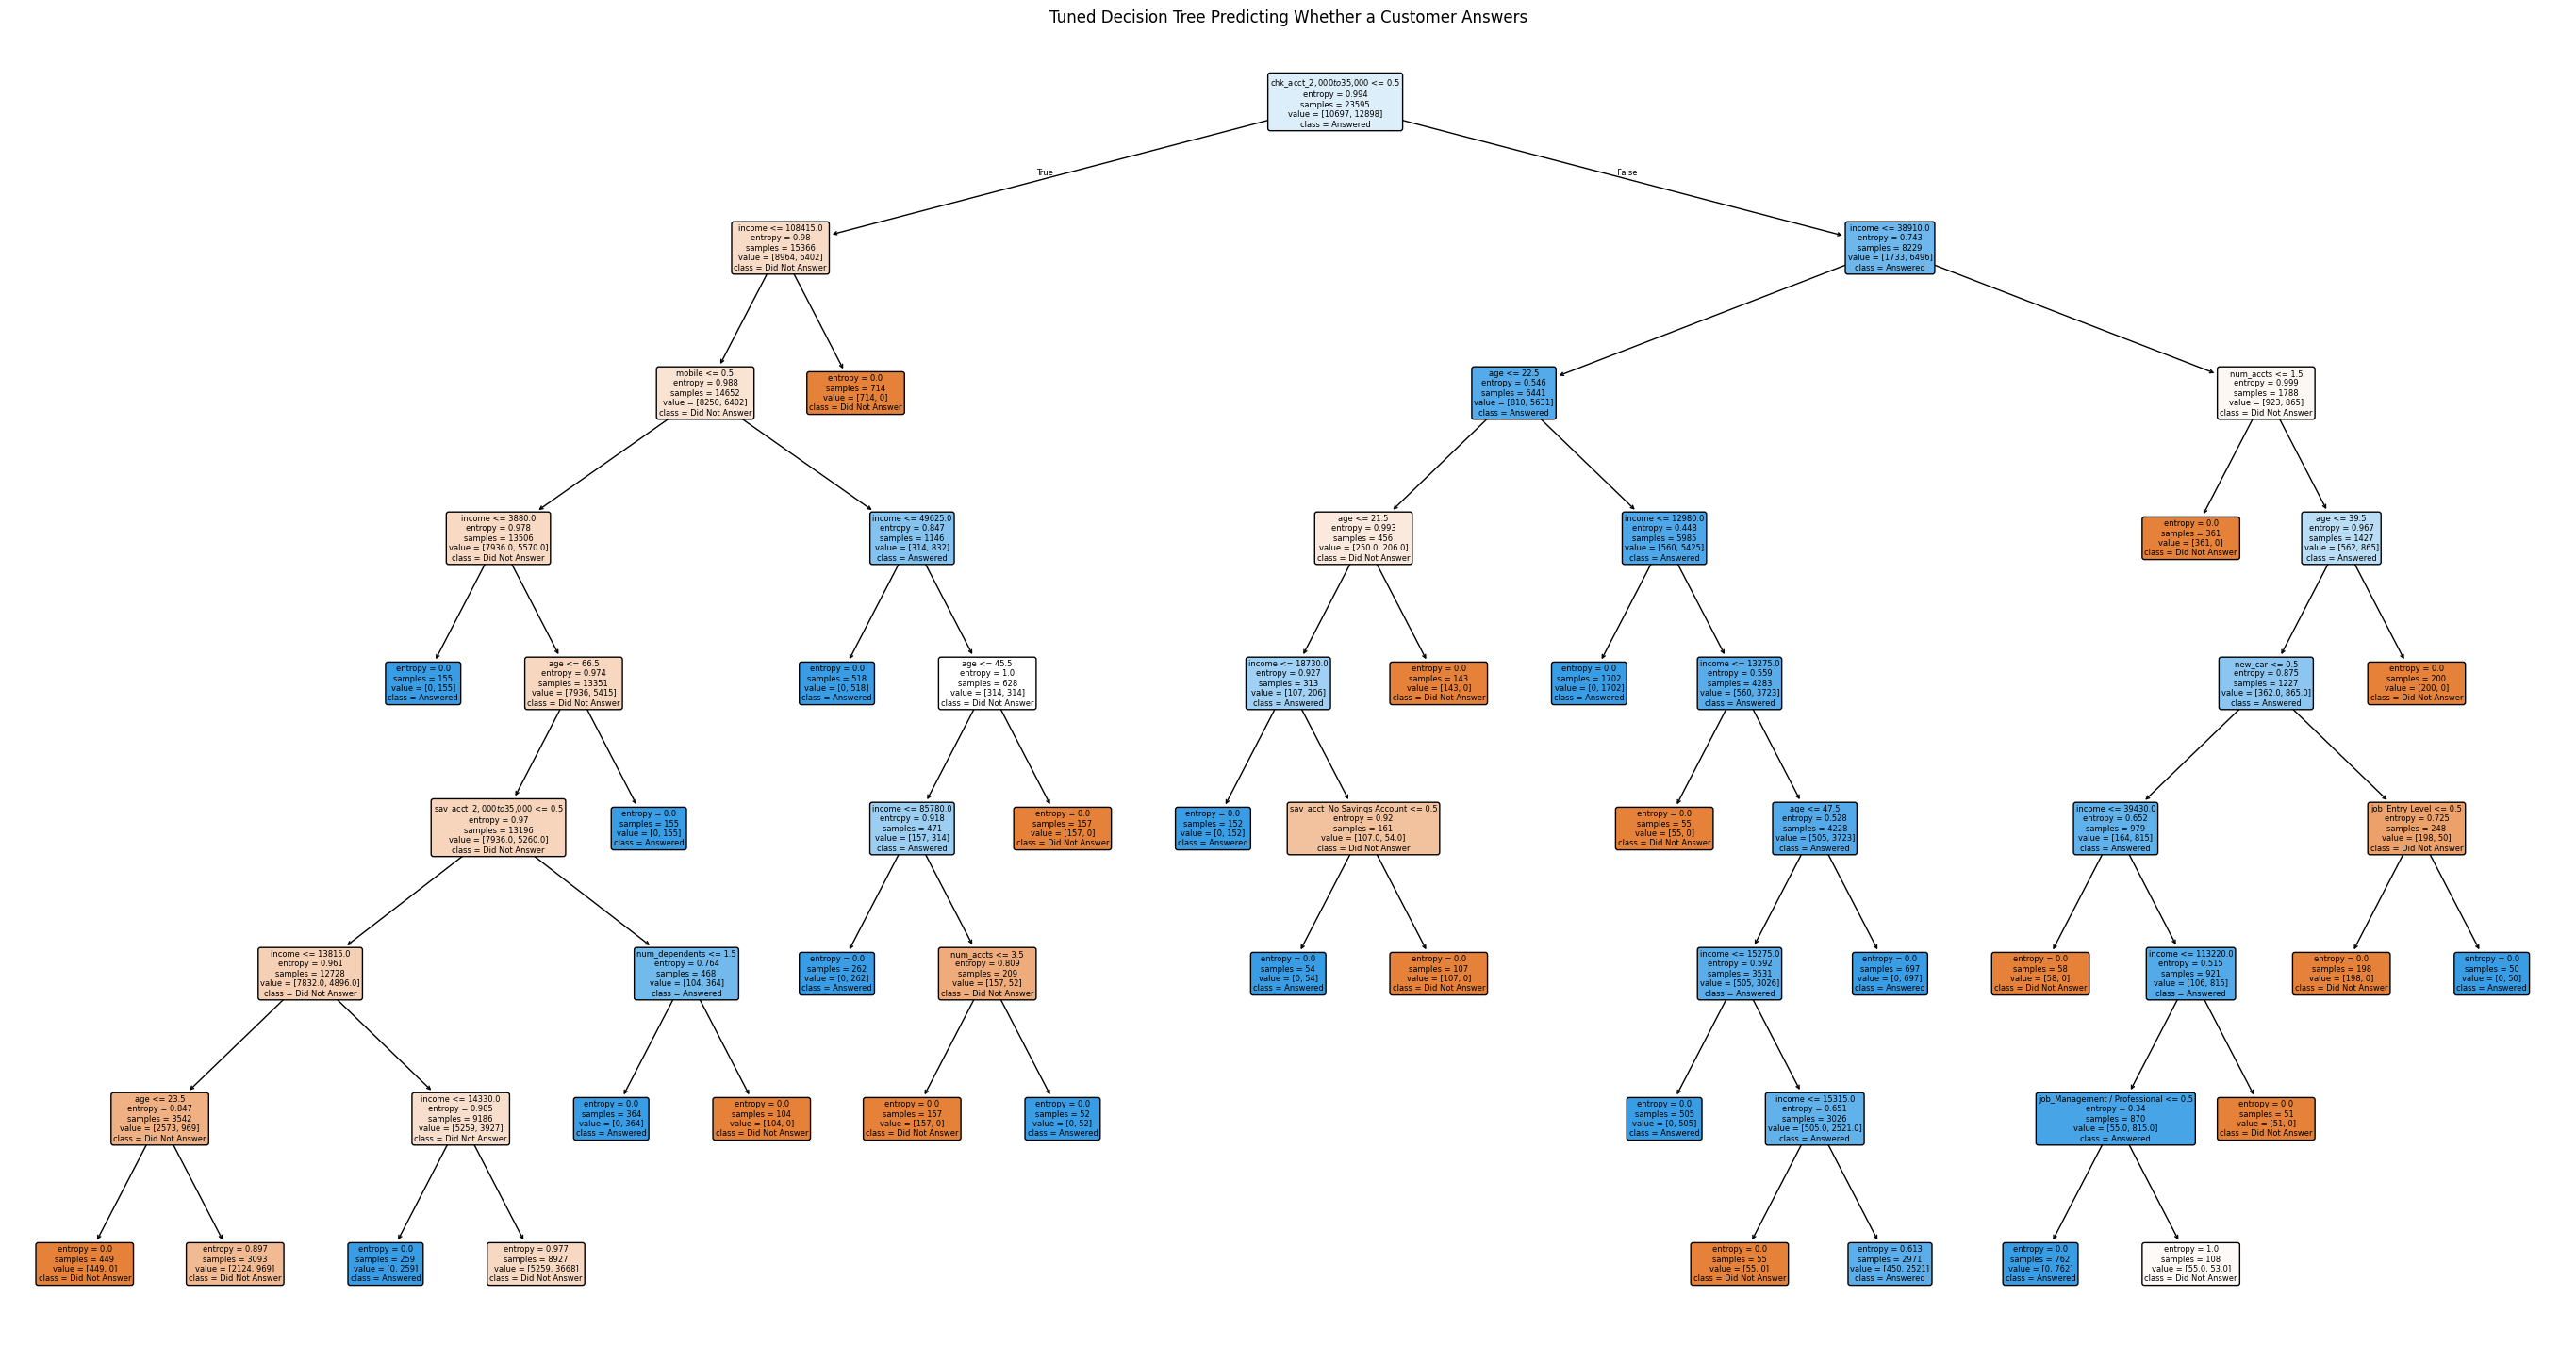

In [ ]:
plt.figure(figsize=(35, 18))

plot_tree(
    tuned_tree_model,
    feature_names=X_train_model.columns,
    class_names=["Did Not Answer", "Answered"],
    filled=True,
    rounded=True,
    fontsize=6
)

plt.title("Tuned Decision Tree Predicting Whether a Customer Answers")
plt.show()


In [ ]:
print(f"Tuned tree accuracy: {tuned_accuracy:.2%}")
print(f"Initial tree accuracy: {tree_accuracy:.2%}")

Tuned tree accuracy: 77.56%
Initial tree accuracy: 71.35%


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

2.1 Check for and remove any outliers

2.2 Consider fixing any missing data (should you delete the record or impute the value?)

In [86]:
df_new = pd.read_csv("adviseinvest_new_customer_data.csv")
df_new.shape

(1000, 13)

In [87]:
# Create a cleaned copy of the new-customer data
df_new_clean = df_new.copy()

# Remove invalid outlier values
df_new_clean = df_new_clean[
    (df_new_clean["income"] > 0) &
    (df_new_clean["age"] <= 100) &
    (df_new_clean["num_accts"] < 5)
]

# Remove missing new_car values, if any
df_new_clean = df_new_clean.dropna(subset=["new_car"])

# Remove duplicate rows, if any
df_new_clean = df_new_clean.drop_duplicates()

# Confirm the result
df_new_clean.shape

(1000, 13)

In [88]:
# Save IDs so they can be attached to predictions later
new_customer_ids = df_new_clean["customer_id"].copy()

# Remove ID before modeling
X_new = df_new_clean.drop(columns="customer_id").copy()

# Match the categorical data types used in training
for col in ["job", "chk_acct", "sav_acct"]:
    X_new[col] = X_new[col].astype("category")

# One-hot encode and match the training-model columns
X_new_model = pd.get_dummies(X_new, drop_first=False, dtype=int)

X_new_model = X_new_model.reindex(
    columns=X_train_model.columns,
    fill_value=0
)

# Predict whether each new customer will answer
new_predictions = tuned_tree_model.predict(X_new_model)

# Attach predictions to customer IDs
prediction_results = pd.DataFrame({
    "customer_id": new_customer_ids,
    "predicted_answered": new_predictions
})

prediction_results.head()

,customer_id,predicted_answered
0,H1597,False
1,P1446,False
2,E1492,False
3,W5143,False
4,W4927,False


In [89]:
prediction_results["predicted_answered"].value_counts()

,count
predicted_answered,
False,894
True,106


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 There was a $47K difference if we used the model, so maybe not.

6.2 The business could estimate the likelihood for a customer to answer and staff accordingly.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [90]:
!jupyter nbconvert --to html "IS4487_Shingi_assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook IS4487_Shingi_assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 1647529 bytes to IS4487_Shingi_assignment_10_classification.html
